In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
root=Path("..")/"Experiment_Results"/"HasilEksperimenTahap2"/"Tahap2A"
sources = {
    "Crossover": root / "Crossover",
    "Population_500": root / "Population" / "500",
}
dataframes=[]
for source_name, folder in sources.items():
    csv_files = sorted(folder.rglob("*.csv"))
    print(f"{source_name}: ditemukan {len(csv_files)} file CSV")

    for csv_file in csv_files:
        df = pd.read_csv(csv_file)

        # Menyimpan asal data agar baris gabungan bisa dilacak
        df["source_group"] = source_name
        df["source_file"] = str(csv_file.relative_to(root))

        dataframes.append(df)
if dataframes:
    df_all=pd.concat(dataframes, ignore_index=True)
else:
    df_all=pd.DataFrame()
    print("Tidak ada file CSV yang berhasil dibaca.")

Crossover: ditemukan 36 file CSV
Population_500: ditemukan 12 file CSV


In [3]:
df_M04_crossover=df_all[df_all["model_id"]=="M04"].copy()
summary_M04_Crossover=df_M04_crossover.groupby(["grid_rows", "pc", "map_type"], as_index=False).agg(
    mean_cost=("best_cost", "mean"),
    best_run=("best_cost", "min"),
    worst_run=("best_cost", "max"),
    std_cost=("best_cost", "std"),
    total_runs=("best_cost", "count")
)
display(summary_M04_Crossover)

,grid_rows,pc,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
0,10,0.80,Cluster,2.500000,2.500000,2.500000,0.000000,30
1,10,0.80,Maze,3.333333,3.333333,3.333333,0.000000,30
2,10,0.80,Random,2.596032,2.416667,2.857143,0.159506,60
3,10,0.85,Cluster,2.500000,2.500000,2.500000,0.000000,30
4,10,0.85,Maze,3.333333,3.333333,3.333333,0.000000,30
5,10,0.85,Random,2.595437,2.416667,2.785714,0.151926,60
6,10,0.90,Cluster,2.500000,2.500000,2.500000,0.000000,30
7,10,0.90,Maze,3.338889,3.333333,3.500000,0.030429,30
8,10,0.90,Random,2.591468,2.416667,2.857143,0.167808,60
9,10,0.95,Cluster,2.500000,2.500000,2.500000,0.000000,30


In [4]:
table_random=summary_M04_Crossover[summary_M04_Crossover["map_type"]=="Random"].sort_values("pc")
display(table_random)
table_cluster=summary_M04_Crossover[summary_M04_Crossover["map_type"]=="Cluster"].sort_values("pc")
display(table_cluster)
table_Maze=summary_M04_Crossover[summary_M04_Crossover["map_type"]=="Maze"].sort_values("pc")
display(table_Maze)

,grid_rows,pc,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
2,10,0.80,Random,2.596032,2.416667,2.857143,0.159506,60
14,20,0.80,Random,6.251282,6.025000,6.564103,0.220510,60
26,40,0.80,Random,6.690134,6.544872,6.943750,0.114609,60
17,20,0.85,Random,6.249145,6.025000,6.487179,0.218418,60
29,40,0.85,Random,6.674145,6.512821,6.875000,0.100389,60
5,10,0.85,Random,2.595437,2.416667,2.785714,0.151926,60
20,20,0.90,Random,6.249989,6.025000,6.487179,0.218066,60
8,10,0.90,Random,2.591468,2.416667,2.857143,0.167808,60
32,40,0.90,Random,6.670069,6.532051,6.850000,0.098535,60
11,10,0.95,Random,2.596230,2.416667,2.857143,0.156901,60


,grid_rows,pc,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
0,10,0.80,Cluster,2.500000,2.500000,2.500000,0.000000,30
12,20,0.80,Cluster,4.791892,4.783784,4.810811,0.012597,30
24,40,0.80,Cluster,5.510108,5.445161,5.741935,0.056598,30
15,20,0.85,Cluster,4.790090,4.783784,4.810811,0.011627,30
27,40,0.85,Cluster,5.491828,5.451613,5.638710,0.034543,30
3,10,0.85,Cluster,2.500000,2.500000,2.500000,0.000000,30
18,20,0.90,Cluster,4.786486,4.783784,4.810811,0.008247,30
6,10,0.90,Cluster,2.500000,2.500000,2.500000,0.000000,30
30,40,0.90,Cluster,5.483226,5.451613,5.587097,0.029848,30
9,10,0.95,Cluster,2.500000,2.500000,2.500000,0.000000,30


,grid_rows,pc,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
1,10,0.80,Maze,3.333333,3.333333,3.333333,0.000000,30
13,20,0.80,Maze,6.812821,6.794872,6.846154,0.015281,30
25,40,0.80,Maze,6.900690,6.841379,7.027586,0.051149,30
16,20,0.85,Maze,6.811111,6.794872,6.846154,0.015768,30
28,40,0.85,Maze,6.889655,6.834483,6.958621,0.036268,30
4,10,0.85,Maze,3.333333,3.333333,3.333333,0.000000,30
19,20,0.90,Maze,6.808547,6.794872,6.846154,0.016123,30
7,10,0.90,Maze,3.338889,3.333333,3.500000,0.030429,30
31,40,0.90,Maze,6.888966,6.841379,6.986207,0.037132,30
10,10,0.95,Maze,3.333333,3.333333,3.333333,0.000000,30


In [5]:
summary_M04_Crossover["rank_mean_cost"] = (
    summary_M04_Crossover
    .groupby(["grid_rows", "map_type"])["mean_cost"]
    .rank(method="average", ascending=True)
)
avg_rank_M04 = (
    summary_M04_Crossover
    .groupby("pc", as_index=False)
    .agg(
        avg_rank_mean=("rank_mean_cost", "mean"),
        avg_mean_cost=("mean_cost", "mean"),
        avg_std_cost=("std_cost", "mean"),
        jumlah_kombinasi=("rank_mean_cost", "count")
    )
    .sort_values(["avg_mean_cost"])
)
display(avg_rank_M04)

,pc,avg_rank_mean,avg_mean_cost,avg_std_cost,jumlah_kombinasi
3,0.95,1.722222,5.033277,0.065179,9
2,0.90,2.166667,5.035293,0.067354,9
1,0.85,2.611111,5.037194,0.063215,9
0,0.80,3.500000,5.042921,0.070028,9


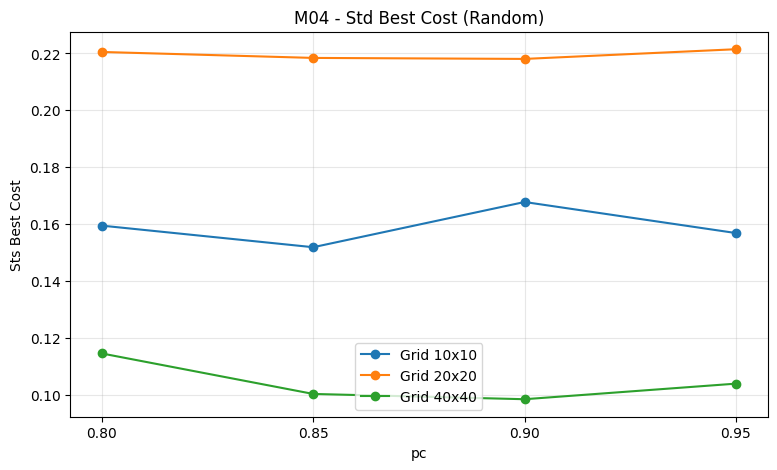

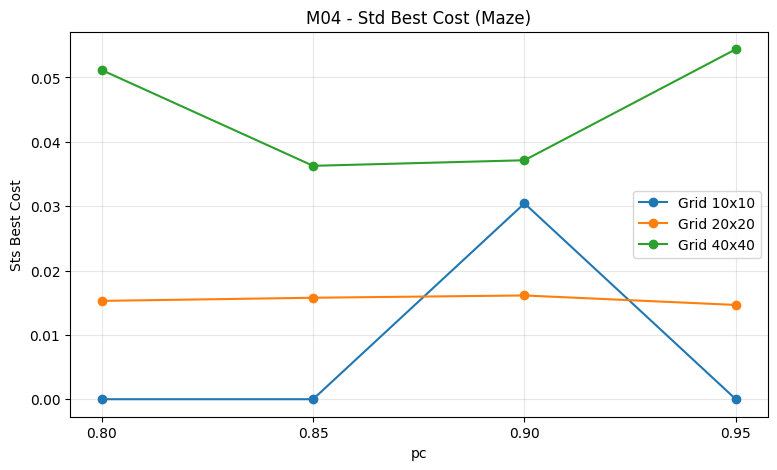

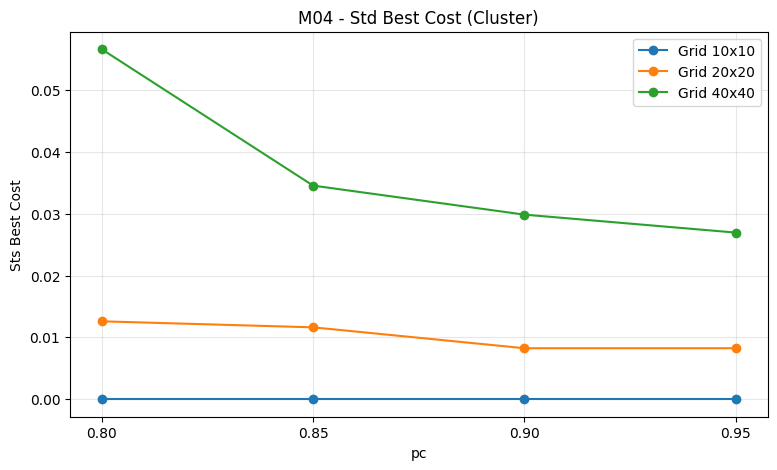

In [6]:
#std cost
map_types = ["Random", "Maze", "Cluster"]

for map_type in map_types:
    data = summary_M04_Crossover[
        summary_M04_Crossover["map_type"] == map_type
    ].copy()

    plt.figure(figsize=(9, 5))

    for grid_rows in sorted(data["grid_rows"].unique()):
        data_size = (
            data[data["grid_rows"] == grid_rows]
            .sort_values("pc")
        )

        plt.plot(
            data_size["pc"],
            data_size["std_cost"],
            marker="o",
            label=f"Grid {grid_rows}x{grid_rows}"
        )

    plt.title(f"M04 - Std Best Cost ({map_type})")
    plt.xlabel("pc")
    plt.ylabel("Sts Best Cost")
    plt.xticks(sorted(data["pc"].unique()))
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.show()

In [7]:
summary_M04_Crossover["rank_std_cost"] = (
    summary_M04_Crossover
    .groupby(["grid_rows", "map_type"])["std_cost"]
    .rank(method="average", ascending=True)
)

avg_rank_M04_std = (
    summary_M04_Crossover
    .groupby("pc", as_index=False)
    .agg(
        avg_rank_std=("rank_std_cost", "mean"),
        avg_std_cost=("std_cost", "mean"),
        jumlah_kombinasi=("rank_std_cost", "count")
    )
    .sort_values([ "avg_std_cost"])
)

print(avg_rank_M04_std)

     pc  avg_rank_std  avg_std_cost  jumlah_kombinasi
1  0.85      2.166667      0.063215                 9
3  0.95      2.388889      0.065179                 9
2  0.90      2.388889      0.067354                 9
0  0.80      3.055556      0.070028                 9


In [8]:
summary_M04_time_crossover=(df_M04_crossover.groupby(["grid_rows","pc", "map_type"], as_index=False).agg(
        mean_execTime=("execution_time_ms", "mean"),
        best_execTime=("execution_time_ms", "min"),
        worst_execTime=("execution_time_ms", "max"),
        std_Time=("execution_time_ms", "std"),
        total_runs=("execution_time_ms", "count")
    ))
display(summary_M04_time_crossover)

avg_time_by_population_m04 = (
    summary_M04_time_crossover
    .groupby("pc", as_index=False)
    .agg(
        avg_execTime=("mean_execTime", "mean"),
        avg_std_time=("std_Time", "mean"),
        jumlah_kombinasi=("mean_execTime", "count")
    )
    .sort_values("avg_execTime")
)
display(avg_time_by_population_m04)
summary_time_pivot = summary_M04_time_crossover.pivot(
    index=["grid_rows", "pc"],
    columns="map_type",
    values="mean_execTime"
)
display(summary_time_pivot)

avg_time_by_map = (
    summary_M04_time_crossover
    .groupby(["map_type", "pc"], as_index=False)
    .agg(
        avg_execTime=("mean_execTime", "mean"),
        avg_std_time=("std_Time", "mean"),
        jumlah_kombinasi=("mean_execTime", "count")
    )
    .sort_values(["map_type", "avg_execTime"])
)

print(avg_time_by_map)

,grid_rows,pc,map_type,mean_execTime,best_execTime,worst_execTime,std_Time,total_runs
0,10,0.80,Cluster,19.833333,10,47,9.203011,30
1,10,0.80,Maze,18.166667,9,34,6.373887,30
2,10,0.80,Random,25.566667,11,53,10.519339,60
3,10,0.85,Cluster,18.900000,10,41,8.937908,30
4,10,0.85,Maze,16.400000,9,29,5.654415,30
5,10,0.85,Random,28.083333,12,55,11.864049,60
6,10,0.90,Cluster,18.500000,9,40,7.767084,30
7,10,0.90,Maze,18.233333,10,34,6.841473,30
8,10,0.90,Random,25.133333,9,60,10.278275,60
9,10,0.95,Cluster,20.833333,11,43,9.161702,30


,pc,avg_execTime,avg_std_time,jumlah_kombinasi
0,0.80,3085.398148,647.451085,9
3,0.95,3499.348148,686.921158,9
1,0.85,3511.403704,669.724332,9
2,0.90,3562.774074,647.369478,9


map_type             Cluster         Maze        Random
grid_rows pc                                           
10        0.80     19.833333    18.166667     25.566667
          0.85     18.900000    16.400000     28.083333
          0.90     18.500000    18.233333     25.133333
          0.95     20.833333    18.900000     23.983333
20        0.80    108.933333   106.966667    135.400000
          0.85    118.100000   112.366667    136.000000
          0.90    119.100000   116.466667    129.950000
          0.95    142.133333   148.133333    130.216667
40        0.80  10253.000000  7773.166667   9327.550000
          0.85  10618.433333  9464.666667  11089.683333
          0.90  10835.333333  8877.933333  11924.316667
          0.95   9872.866667  9431.733333  11705.333333

   map_type    pc  avg_execTime  avg_std_time  jumlah_kombinasi
3   Cluster  0.95   3345.277778    774.147672                 3
0   Cluster  0.80   3460.588889    726.904452                 3
1   Cluster  0.85   3585.144444    755.765894                 3
2   Cluster  0.90   3657.644444    733.774523                 3
4      Maze  0.80   2632.766667    665.023768                 3
6      Maze  0.90   3004.211111    502.772016                 3
5      Maze  0.85   3197.811111    428.350457                 3
7      Maze  0.95   3199.588889    587.224721                 3
8    Random  0.80   3162.838889    550.425034                 3
9    Random  0.85   3751.255556    825.056644                 3
11   Random  0.95   3953.177778    699.391080                 3
10   Random  0.90   4026.466667    705.561896                 3
